In [1]:
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent

import pandas as pd

# pd.set_option('display.max_columns', None)  # none은 제한값 자리(몇개 열까지 보여줄까)
# pd.set_option('display.max_rows', None)

# ============================================================
# 0. 데이터 불러오기
# ============================================================

train = pd.read_parquet(PROJECT_ROOT / 'parqueted_data' / 'train_split.parquet')

train_fe = pd.read_parquet(PROJECT_ROOT / 'parqueted_data' / '1_train_fe.parquet')

In [2]:
# ============================================================
# 1. 컬럼 분리
# ============================================================

# 시계열 컬럼군
time_cols = [
    'wl_t',          # 수위데이터 대표
    'sfc_rain_1h',   # 육상 누적강수데이터 대표
    'imerg_rain_1h', # 레이더 누적강수데이터 대표
    'radar_reflectivity_mean', # 레이더반사도 대표
    'radar_reflectivity_p95', # 레이더반사도 대표
    'target_maxrise_6h' # 종속변수: 수위상승량
]

# 수위 컬럼군
wl_cols_EDA = [
    'wl_t',
    'wl_t_minus_1h',
    'wl_t_minus_3h',
    'wl_t_minus_6h',
    'wl_t_minus_12h',
    'wl_t_minus_24h',
    'target_maxrise_6h',
]

# 수위차분(wl_diff) 컬럼군
wl_diff_cols_EDA = [
    'wl_t',
    'wl_diff_1h',
    'wl_diff_3h',
    'wl_diff_6h',
    'wl_diff_12h',
    'wl_diff_24h',
    'target_maxrise_6h',
]


# 강수 컬럼군
rain_cols = [
    # IMERG강우
    'imerg_rain_1h',
    'imerg_rain_6h',
    'imerg_rain_24h',
    # 지상강우
    'sfc_rain_1h',
    'sfc_rain_6h',
    'sfc_rain_24h',
    # 레이더 반사도
    'radar_reflectivity_mean',
    'radar_reflectivity_p95',
    'radar_reflectivity_ge20_fraction'
]

# 강우강도 컬럼군
rain_int_cols = [
    'imerg_rain_1h',
    'imerg_int_1to6h',
    'imerg_int_6to24h',
    'sfc_rain_1h',
    'sfc_int_1to6h',
    'sfc_int_6to24h'
]

# 환경 컬럼군
env_cols = [
    'cat_area',       # km²
    'wsarea',         # km²
    'mean_elevation', # m
    'mean_slope',     # °
    'urban_ratio',    # %
    'forest_ratio',   # %
    'stream_order'
]

print(len(wl_cols_EDA), len(wl_diff_cols_EDA), len(rain_cols), len(env_cols))

7 7 9 7


In [5]:
# ============================================================
# 2. 수위변수 및 종속변수간 상관계수
# ============================================================

print("피어슨 상관계수: 수위변수군")
print(
    train[wl_cols_EDA]
    .corr(
        method='pearson'
    )
    .round(2)
    .to_csv(sep='\t')
)
print()

print("스피어만 상관계수: 수위변수군")
print(
    train[wl_cols_EDA]
    .corr(
        method='spearman'
    )
    .round(2)
    .to_csv(sep='\t')
)
# 정리 필요
# 수위변수군 내부적으로 강력한 상관성이 확인됨
# 그러나 개별 변수의 종속변수에 대한 상관성은 미미함
# -> 개별값보다 시차별 수위 변화에 대한 정보가 예측에 활용됐을 가능성
# -> 차분에 의한 파생변수 생성 검토 필요


피어슨 상관계수: 수위변수군
	wl_t	wl_t_minus_1h	wl_t_minus_3h	wl_t_minus_6h	wl_t_minus_12h	wl_t_minus_24h	target_maxrise_6h
wl_t	1.0	1.0	1.0	1.0	1.0	1.0	-0.03
wl_t_minus_1h	1.0	1.0	1.0	1.0	1.0	1.0	-0.03
wl_t_minus_3h	1.0	1.0	1.0	1.0	1.0	1.0	-0.03
wl_t_minus_6h	1.0	1.0	1.0	1.0	1.0	1.0	-0.02
wl_t_minus_12h	1.0	1.0	1.0	1.0	1.0	1.0	-0.03
wl_t_minus_24h	1.0	1.0	1.0	1.0	1.0	1.0	-0.03
target_maxrise_6h	-0.03	-0.03	-0.03	-0.02	-0.03	-0.03	1.0


스피어만 상관계수: 수위변수군
	wl_t	wl_t_minus_1h	wl_t_minus_3h	wl_t_minus_6h	wl_t_minus_12h	wl_t_minus_24h	target_maxrise_6h
wl_t	1.0	1.0	0.98	0.96	0.96	0.94	-0.01
wl_t_minus_1h	1.0	1.0	0.99	0.96	0.96	0.94	-0.03
wl_t_minus_3h	0.98	0.99	1.0	0.98	0.96	0.94	-0.03
wl_t_minus_6h	0.96	0.96	0.98	1.0	0.96	0.94	-0.01
wl_t_minus_12h	0.96	0.96	0.96	0.96	1.0	0.98	-0.03
wl_t_minus_24h	0.94	0.94	0.94	0.94	0.98	1.0	-0.03
target_maxrise_6h	-0.01	-0.03	-0.03	-0.01	-0.03	-0.03	1.0



In [6]:
# ============================================================
# 3. 수위 차분변수(wl_diff) 및 종속변수 상관계수
# ============================================================

print("피어슨 상관계수: 수위차분(wl_diff)변수군")
print(
    train_fe[wl_diff_cols_EDA]
    .corr(
        method='pearson'
    )
    .round(2)
    .to_csv(sep='\t')
)
print()

print("스피어만 상관계수: 수위차분(wl_diff)변수군")
print(
    train_fe[wl_diff_cols_EDA]
    .corr(
        method='spearman'
    )
    .round(2)
    .to_csv(sep='\t')
)

# wl_diff_6h와 종속변수(6시간 최대 수위변동)가 피어슨계수는 -0.29,
# 스피어만계수는 0.23으로 독특함
# 두 변수간의 산점도 필요

피어슨 상관계수: 수위차분(wl_diff)변수군
	wl_t	wl_diff_1h	wl_diff_3h	wl_diff_6h	wl_diff_12h	wl_diff_24h	target_maxrise_6h
wl_t	1.0	0.0	0.01	0.01	0.01	0.02	-0.03
wl_diff_1h	0.0	1.0	0.78	0.37	0.18	0.09	0.2
wl_diff_3h	0.01	0.78	1.0	0.73	0.31	0.21	-0.03
wl_diff_6h	0.01	0.37	0.73	1.0	0.49	0.4	-0.29
wl_diff_12h	0.01	0.18	0.31	0.49	1.0	0.8	0.1
wl_diff_24h	0.02	0.09	0.21	0.4	0.8	1.0	0.08
target_maxrise_6h	-0.03	0.2	-0.03	-0.29	0.1	0.08	1.0


스피어만 상관계수: 수위차분(wl_diff)변수군
	wl_t	wl_diff_1h	wl_diff_3h	wl_diff_6h	wl_diff_12h	wl_diff_24h	target_maxrise_6h
wl_t	1.0	0.02	0.05	0.08	0.09	0.1	-0.01
wl_diff_1h	0.02	1.0	0.74	0.54	0.35	0.22	0.4
wl_diff_3h	0.05	0.74	1.0	0.76	0.51	0.35	0.34
wl_diff_6h	0.08	0.54	0.76	1.0	0.68	0.49	0.23
wl_diff_12h	0.09	0.35	0.51	0.68	1.0	0.68	0.2
wl_diff_24h	0.1	0.22	0.35	0.49	0.68	1.0	0.14
target_maxrise_6h	-0.01	0.4	0.34	0.23	0.2	0.14	1.0



In [ ]:
# 3-4. 이상치가 확인되어 나머지 수위차분변수에도 이상치가 있는지 확인
# 1, 3, 6, 12, 24h는 모두 연계돼 있기때문

import matplotlib.pyplot as plt

wl_diff_cols_only = [
    col for col in wl_diff_cols_EDA
    if col not in ['wl_t', 'target_maxrise_6h']
]

fig, axes = plt.subplots(
    len(wl_diff_cols_only),
    1,
    figsize=(
        6,
        4 * len(wl_diff_cols_only)
    )
)

if len(wl_diff_cols_only) == 1: # cols에 한개 열만 오면 axes = [ax1, ax2...]만 반환
    axes = [axes]  # axes = [[ax1, ax2]]가 돼야 행열(0행 0, 1열) 접근이 가능

for i, col in enumerate(wl_diff_cols_only):
    x = train_fe[col].dropna()  # 플롯을 여러개 그릴 예정, 플롯할 데이터를 하나의 변수로 묶어놓기(col임을 주의)

    axes[i].scatter(x, train_fe['target_maxrise_6h']) 
    axes[i].tick_params(labelsize = 10)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('target_maxrise_6h')

plt.tight_layout()  # 자동 간격조정(배치관리)
plt.show()


In [ ]:
# 3-4. 이상치 검증을 위해 전후 데이터 확인
# 시계열 컬럼군

cond_wl_out_all = ( 
    train_fe[wl_diff_cols_only] < -10  # 다중값 비교: (조건식).any() or all()
).any(axis=1)
print(f"수위차분변수 극단값 개수: {len(train_fe.loc[cond_wl_out_all])}")
display(train_fe.loc[cond_wl_out_all])  # 하나의 관측소 두개의 강우사상으로 확인
print()

# 이상치 관측소 2개 지정
cond_wl_out_station = train_fe['station_id'] == 'ST0445'
cond_wl_out_station2 = train_fe['station_id'] == 'ST0066'

# ST0445 이상치 전후 시계열 탐색
cond_wl_out_time1 = (train_fe['timestamp'] > '2100-08-09 00:00:00') & (train_fe['timestamp'] < '2100-08-10 00:00:00')
cond_wl_out_time2 = (train_fe['timestamp'] > '2102-09-17 00:00:00') & (train_fe['timestamp'] < '2102-09-19 00:00:00')
cond_wl_out_time3 = (train_fe['timestamp'] > '2101-11-02 00:00:00') & (train_fe['timestamp'] < '2101-11-03 00:00:00')

print("ST0445 이상치 전후 시계열(강우사상 3개)")
display(
    train_fe.loc[
        cond_wl_out_station & (
             cond_wl_out_time1 | cond_wl_out_time2 | cond_wl_out_time3
        )
    ][['timestamp'] + wl_diff_cols_EDA]
)

# ST0066 이상치 전후 시계열 탐색
print("ST0066 이상치 전후 시계열(강우사상 1개)")
cond_wl_out_station2 = train_fe['station_id'] == 'ST0066'
cond_wl_out_time4 = (train_fe['timestamp'] > '2102-03-31 00:00:00') & (train_fe['timestamp'] < '2102-04-02 00:00:00')
display(
    train_fe.loc[
        cond_wl_out_station2 & cond_wl_out_time4
    ][['timestamp'] + wl_diff_cols_EDA]
)

In [64]:
# ST0445 이상치 탐색
# train_fe.loc[cond_wl_out_station, ['timestamp'] + wl_diff_cols_EDA].head(50)
# ST0445 수위변수 이상치 탐색: 17.63이 이상치로 확인됨
# cond_wl_out_station = train_fe['station_id'] == 'ST0445'

wl_cols_only = [
    col for col in wl_cols_EDA
    if col not in ['target_maxrise_6h']
]
# print(wl_cols_only)

train_fe.loc[cond_wl_out_station, 'wl_t'].describe()
train_fe.loc[cond_wl_out_station, 'wl_t'].quantile([0.9, 0.95, 0.99, 1.0])

cond_wl_out_ST0445 = (train_fe[wl_cols_only] > 15).any(axis = 1) # 행별집계를 위함

train_fe.loc[
    (cond_wl_out_ST0445 & cond_wl_out_station),
    wl_cols_only
].sort_values(
    by = 'wl_t', 
    ascending = False
)

# 수위값에 17.63은 이상치로 확정, 15 이상으로 잡으면 됨


,wl_t,wl_t_minus_1h,wl_t_minus_3h,wl_t_minus_6h,wl_t_minus_12h,wl_t_minus_24h
row_id,,,,,,
TR_000639479,17.63,17.63,17.63,17.63,17.63,17.63
TR_000561875,17.63,17.63,17.63,17.63,17.63,17.63
TR_000258437,17.63,17.63,17.63,17.63,17.63,17.63
TR_000386997,2.61,2.61,17.63,17.63,17.63,17.63
TR_000652873,2.61,2.61,17.63,17.63,17.63,17.63
TR_000333157,2.61,2.59,2.61,17.63,17.63,17.63
TR_000589829,2.61,17.63,17.63,17.63,17.63,17.63
TR_000202521,2.61,2.61,17.63,17.63,17.63,17.63
TR_000182368,2.59,2.61,2.61,17.63,17.63,17.63


In [67]:
# ST0066 이상치 탐색
# train_fe.loc[cond_wl_out_station2, ['timestamp'] + wl_diff_cols_EDA].head(50)
# ST0445 수위변수 이상치 탐색: 17.63이 이상치로 확인됨
# cond_wl_out_station2 = train_fe['station_id'] == 'ST0066'

# print(wl_cols_only)

train_fe.loc[cond_wl_out_station2, 'wl_t'].describe()
train_fe.loc[cond_wl_out_station2, 'wl_t'].quantile([0.9, 0.95, 0.99, 1.0])

cond_wl_out_ST0066 = (train_fe[wl_cols_only] > 15).any(axis = 1) # 행별집계를 위함

train_fe.loc[
    (cond_wl_out_ST0066 & cond_wl_out_station2),
    wl_cols_only
].sort_values(
    by = 'wl_t', 
    ascending = False
)

# 수위값에 23.56은 이상치로 확정, 15 이상으로 잡으면 됨


,wl_t,wl_t_minus_1h,wl_t_minus_3h,wl_t_minus_6h,wl_t_minus_12h,wl_t_minus_24h
row_id,,,,,,
TR_000480207,23.56,23.53,23.54,23.55,23.54,23.56
TR_000612212,23.56,23.56,23.53,23.54,23.54,23.56
TR_000453262,23.56,23.56,23.53,23.54,23.54,23.55
TR_000575758,23.56,23.56,23.56,23.54,23.54,23.55
TR_000109053,23.56,23.56,23.56,23.53,23.55,23.55
TR_000598901,23.56,23.56,23.56,23.53,23.55,23.55
TR_000536275,23.56,23.56,23.56,23.56,23.55,23.54
TR_000292998,23.56,23.56,23.56,23.56,23.54,23.54
TR_000103144,23.56,23.56,23.56,23.56,23.54,23.54


In [ ]:
# 3-4. 같은 이상치가 val, test 셋에도 있는지 확인 필요: 있음
# 일단 모델링 하고나서 test셋 어떡할지 확인예정

val_fe = pd.read_parquet(PROJECT_ROOT / 'parqueted_data' / '1_val_fe.parquet')
test_fe = pd.read_parquet(PROJECT_ROOT / 'parqueted_data' / '1_test_fe.parquet')

# wl_cols_only = [
#     col for col in wl_cols_EDA
#     if col not in ['target_maxrise_6h']
# ]
# cond_wl_out_station = train_fe['station_id'] == 'ST0445'
# cond_wl_out_station2 = train_fe['station_id'] == 'ST0066'
# cond_wl_out_ST0445 = (train_fe[wl_cols_only] > 7).any(axis = 1)
# cond_wl_out_ST0066 = (train_fe[wl_cols_only] > 15).any(axis = 1)


for name, df in [('train_fe', train_fe), ('val_fe', val_fe), ('test_fe', test_fe)]:
    
    cond_wl_out_station_vt1 = df['station_id'] == 'ST0445'
    cond_wl_out_station_vt2 = df['station_id'] == 'ST0066'
    cond_wl_out_ST0445_vt = (df[wl_cols_only] > 15).any(axis = 1)
    cond_wl_out_ST0066_vt = (df[wl_cols_only] > 15).any(axis = 1)

    df.loc[
        (cond_wl_out_station_vt1 & cond_wl_out_ST0445_vt) |
        (cond_wl_out_station_vt2 & cond_wl_out_ST0066_vt)
    ]

    print(
        f"{name}의 wl_t 이상치 개수: "
        f"{(
            (cond_wl_out_station_vt1 & cond_wl_out_ST0445_vt) |
            (cond_wl_out_station_vt2 & cond_wl_out_ST0066_vt)
     ).sum()}"
)

train_fe의 wl_t 이상치 개수: 32
val_fe의 wl_t 이상치 개수: 0
test_fe의 wl_t 이상치 개수: 14


In [ ]:
# ============================================================
# 3-5. 확인된 이상치(train에만 있음) 제거
# ============================================================

# 이상치 row_id 추출
wl_error_row_id = [
    # ST0445: 12개
    'TR_000639479',
    'TR_000561875',
    'TR_000258437',
    'TR_000386997',
    'TR_000652873',
    'TR_000333157',
    'TR_000589829',
    'TR_000202521',
    'TR_000182368',
    'TR_000682989',
    'TR_000205403',
    'TR_000202940',

    # ST0066: 20개
    'TR_000480207',
    'TR_000612212',
    'TR_000453262',
    'TR_000575758',
    'TR_000109053',
    'TR_000598901',
    'TR_000536275',
    'TR_000292998',
    'TR_000103144',
    'TR_000157390',
    'TR_000622988',
    'TR_000426744',
    'TR_000463562',
    'TR_000165447',
    'TR_000386146',
    'TR_000616893',
    'TR_000446779',
    'TR_000677096',
    'TR_000508034',
    'TR_000437549'
]

print(f"이상치 제거 전 데이터 크기: {train_fe.shape}")

train_fe_v2 = train_fe.drop(
    index = wl_error_row_id
)

print(f"이상치 제거 후 데이터 크기: {train_fe_v2.shape}")

train_fe_v2.to_parquet(PROJECT_ROOT / 'parqueted_data' / '2_train_clean2.parquet')



이상치 제거 전 데이터 크기: (616331, 35)
이상치 제거 후 데이터 크기: (616299, 35)


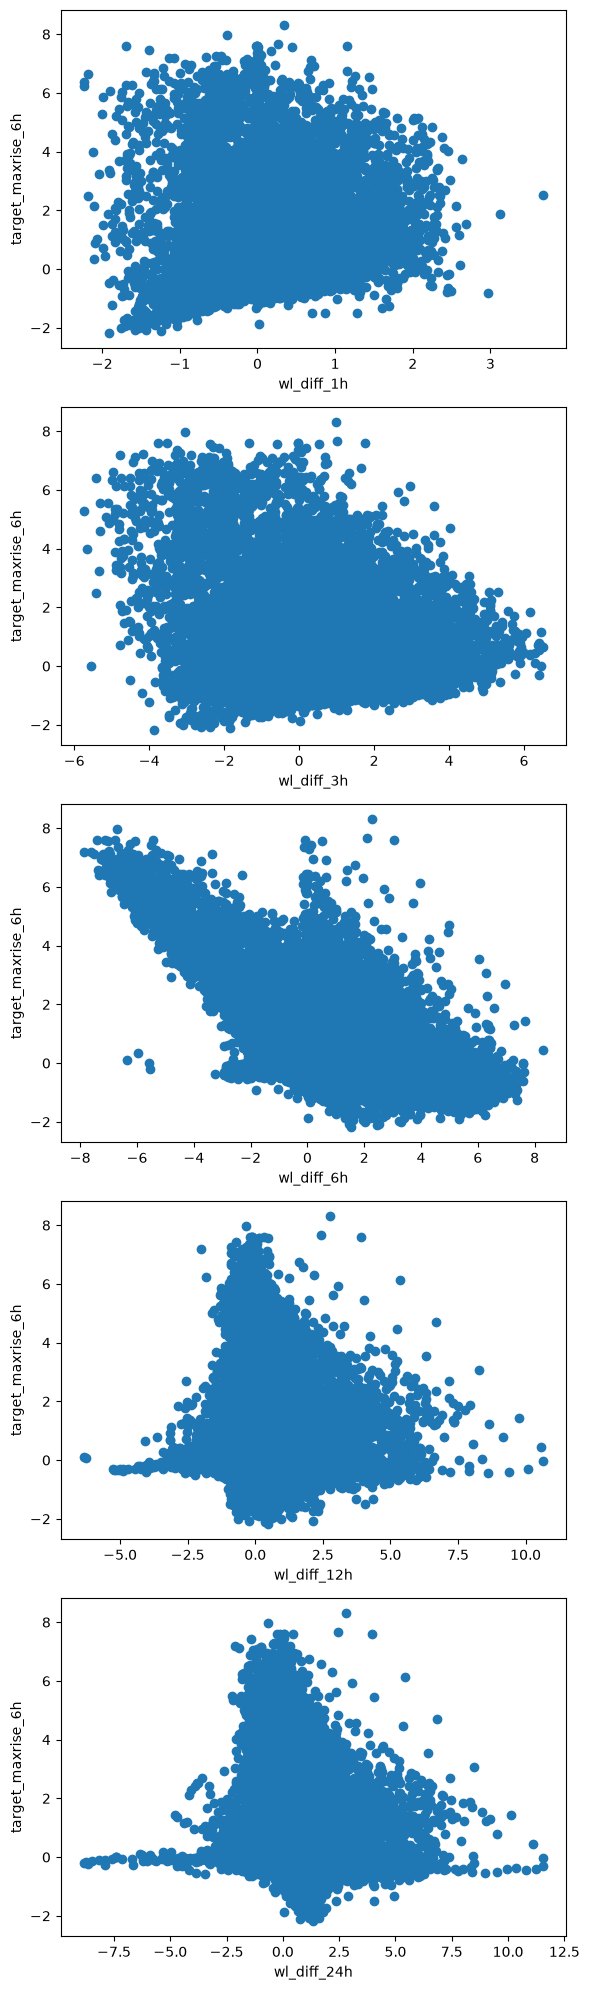

In [76]:
# 이상치 제거 후, 차분변수 데이터들도 이상치가 제거 됐는지 확인

import matplotlib.pyplot as plt

wl_diff_cols_only = [
    col for col in wl_diff_cols_EDA
    if col not in ['wl_t', 'target_maxrise_6h']
]

fig, axes = plt.subplots(
    len(wl_diff_cols_only),
    1,
    figsize=(
        6,
        4 * len(wl_diff_cols_only)
    )
)

if len(wl_diff_cols_only) == 1: # cols에 한개 열만 오면 axes = [ax1, ax2...]만 반환
    axes = [axes]  # axes = [[ax1, ax2]]가 돼야 행열(0행 0, 1열) 접근이 가능

for i, col in enumerate(wl_diff_cols_only):
    x = train_fe_v2[col].dropna()  # 플롯을 여러개 그릴 예정, 플롯할 데이터를 하나의 변수로 묶어놓기(col임을 주의)

    axes[i].scatter(x, train_fe_v2['target_maxrise_6h']) 
    axes[i].tick_params(labelsize = 10)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('target_maxrise_6h')

plt.tight_layout()  # 자동 간격조정(배치관리)
plt.show()


In [71]:
# 3-6. 이상치 제거 후 상관계수: 이상치 제거 전과 동일

print("피어슨 상관계수: 수위차분변수(이상치제거)군")
print(
    train_fe_v2[wl_diff_cols_EDA]
    .corr(
        method='pearson'
    )
    .round(2)
    .to_csv(sep='\t')
)
print()

print("스피어만 상관계수: 수위차분변수(이상치제거)군")
print(
    train_fe_v2[wl_diff_cols_EDA]
    .corr(
        method='spearman'
    )
    .round(2)
    .to_csv(sep='\t')
)

피어슨 상관계수: 수위차분변수(이상치제거)군
	wl_t	wl_diff_1h	wl_diff_3h	wl_diff_6h	wl_diff_12h	wl_diff_24h	target_maxrise_6h
wl_t	1.0	0.0	0.01	0.01	0.01	0.02	-0.03
wl_diff_1h	0.0	1.0	0.78	0.37	0.18	0.09	0.2
wl_diff_3h	0.01	0.78	1.0	0.73	0.3	0.21	-0.03
wl_diff_6h	0.01	0.37	0.73	1.0	0.49	0.39	-0.29
wl_diff_12h	0.01	0.18	0.3	0.49	1.0	0.79	0.1
wl_diff_24h	0.02	0.09	0.21	0.39	0.79	1.0	0.08
target_maxrise_6h	-0.03	0.2	-0.03	-0.29	0.1	0.08	1.0


스피어만 상관계수: 수위차분변수(이상치제거)군
	wl_t	wl_diff_1h	wl_diff_3h	wl_diff_6h	wl_diff_12h	wl_diff_24h	target_maxrise_6h
wl_t	1.0	0.02	0.05	0.08	0.09	0.1	-0.01
wl_diff_1h	0.02	1.0	0.74	0.54	0.35	0.22	0.4
wl_diff_3h	0.05	0.74	1.0	0.76	0.51	0.35	0.34
wl_diff_6h	0.08	0.54	0.76	1.0	0.68	0.49	0.23
wl_diff_12h	0.09	0.35	0.51	0.68	1.0	0.68	0.2
wl_diff_24h	0.1	0.22	0.35	0.49	0.68	1.0	0.14
target_maxrise_6h	-0.01	0.4	0.34	0.23	0.2	0.14	1.0



In [72]:
# 3-7. wl_diff_6h의 수위 상승, 유지, 하강 구간별 종속변수와의 상관계수 분리
# 가설: 피어슨, 스피어만 상관계수의 차이가 큰 이유가 구간별 상관계수가 상이한데서 오는게 아닐까?
# 수위 상승, 유지구간은 피어슨, 스피어만 비슷
# 수위 하강구간에서 큰 차이를 보임

# 수위 상승, 하강 기준을 수위차분값 0.05, -0.05로 임의로 설정
cond_wl_diff_6h_up = train_fe_v2['wl_diff_6h'] > 0.05
cond_wl_diff_6h_0 = train_fe_v2['wl_diff_6h'].between(-0.05, 0.05)
cond_wl_diff_6h_down = train_fe_v2['wl_diff_6h'] < -0.05

for name, cond in [
    ('wl_diff_6h_up', cond_wl_diff_6h_up),
    ('wl_diff_6h_0', cond_wl_diff_6h_0),
    ('wl_diff_6h_down', cond_wl_diff_6h_down)
]:

    print(f"{name}구간")
    print(f"데이터 개수: {cond.sum()}")
    print(
        f"피어슨 상관계수: "
        f"{
            train_fe_v2.loc[cond, ['wl_diff_6h', 'target_maxrise_6h']]
            .corr(method='pearson')
            .round(2)
            .iloc[0, 1]
        }"
    )

    print(
        f"스피어만 상관계수: "
        f"{
            train_fe_v2.loc[cond, ['wl_diff_6h', 'target_maxrise_6h']]
            .corr(method='spearman')
            .round(2)
            .iloc[0, 1]
        }"
    )
    print()

wl_diff_6h_up구간
데이터 개수: 131227
피어슨 상관계수: 0.02
스피어만 상관계수: 0.06

wl_diff_6h_0구간
데이터 개수: 405878
피어슨 상관계수: 0.05
스피어만 상관계수: 0.23

wl_diff_6h_down구간
데이터 개수: 79194
피어슨 상관계수: -0.8
스피어만 상관계수: -0.05



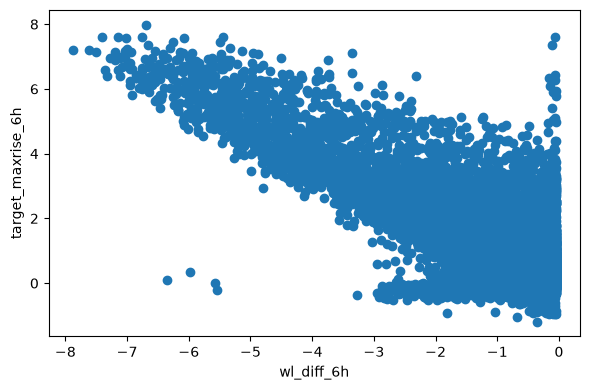

In [73]:
# 3-8. wl_diff_6h의 수위하강 구간(<-0.05) 산점도 확인

# y = -x 그래프의 아랫면이 칼로자른듯 비어있는 형태
# wl_t값이 과소하게 측정돼 6시간 전 후와의 값이 벌어진 것으로 추정되는 상황


fig, ax = plt.subplots(
    1,
    1,
    figsize = (6, 4)
)

ax.scatter(
    train_fe_v2.loc[cond_wl_diff_6h_down, 'wl_diff_6h'],
    train_fe_v2.loc[cond_wl_diff_6h_down, 'target_maxrise_6h'])
ax.set_xlabel('wl_diff_6h')
ax.set_ylabel('target_maxrise_6h')

plt.tight_layout()
plt.show()


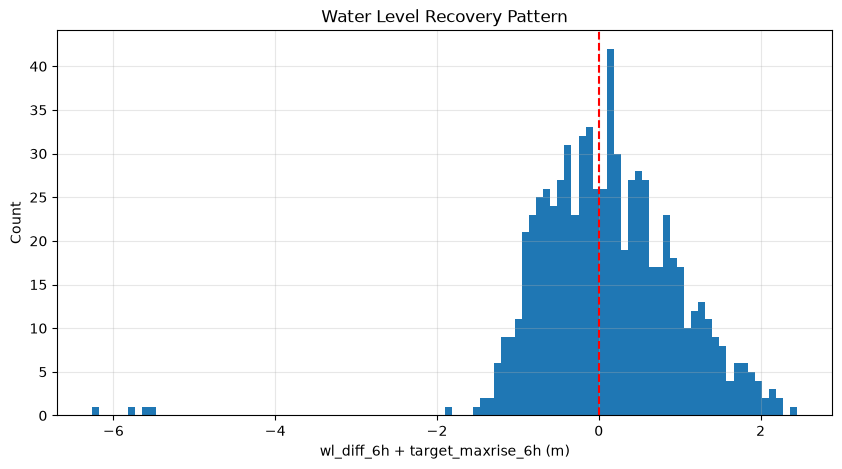

전체 하강 구간: 723개
±0.05m 이내: 4.56%
±0.10m 이내: 9.13%


In [74]:
# ============================================================
# 3-9. 수위 급하강 후 회복 패턴 확인
# ============================================================
# 하강 구간(=4m 미만) 대상

cond_wl_diff_6h_down = train_fe_v2['wl_diff_6h'] < -4

# 수위 하강량 + 향후 6시간 최대 상승량
wl_recovery = (
    train_fe_v2.loc[cond_wl_diff_6h_down, 'wl_diff_6h']
    + train_fe_v2.loc[cond_wl_diff_6h_down, 'target_maxrise_6h']
)

# 히스토그램
plt.figure(figsize=(10, 5))

plt.hist(
    wl_recovery,
    bins=100
)

plt.axvline(0, color='red', linestyle='--')

plt.xlabel('wl_diff_6h + target_maxrise_6h (m)')
plt.ylabel('Count')
plt.title('Water Level Recovery Pattern')
plt.grid(alpha=0.3)

plt.show()

# 0 근처 집중 정도 확인
print(f"전체 하강 구간: {len(wl_recovery):,}개")
print(f"±0.05m 이내: {(wl_recovery.abs() <= 0.05).mean():.2%}")
print(f"±0.10m 이내: {(wl_recovery.abs() <= 0.10).mean():.2%}")

In [17]:
# ============================================================
# 3-10. Train, Val, Test 수위 급하강 패턴 비교
# ============================================================

# 1. 데이터 불러오기 : 앞선 셀들에 다 불러와져 있음

# 2. 6시간 동안 4m 이상 급하강한 데이터 비교
for name, df in [
    ('Train', train_fe_v2),
    ('Val', val_fe),
    ('Test', test_fe)
]:
    cond = df['wl_diff_6h'] < -4

    print(f"\n{name}")
    print(f"전체 데이터: {len(df):,}개")
    print(f"4m 초과 급하강: {cond.sum():,}개")
    print(f"급하강 비율: {cond.mean():.3%}")
    print(f"해당 관측소: {df.loc[cond, 'station_id'].nunique()}개")

    # 4m 초과 급하강 관측소별 발생 횟수

for name, df in [
    ('Train', train_fe_v2),
    ('Val', val_fe),
    ('Test', test_fe)
]:
    print(f"\n{name}")

    print(
        df.loc[
            df['wl_diff_6h'] < -4,
            'station_id'
        ]
        .value_counts()
        .to_string()
    )


Train
전체 데이터: 616,318개
4m 초과 급하강: 723개
급하강 비율: 0.117%
해당 관측소: 5개

Val
전체 데이터: 133,325개
4m 초과 급하강: 159개
급하강 비율: 0.119%
해당 관측소: 3개

Test
전체 데이터: 186,263개
4m 초과 급하강: 242개
급하강 비율: 0.130%
해당 관측소: 3개

Train
station_id
ST0358    311
ST0292    210
ST0326    198
ST0158      3
ST0089      1

Val
station_id
ST0358    71
ST0326    46
ST0292    42

Test
station_id
ST0358    100
ST0292     75
ST0326     67


In [18]:
# ============================================================
# 3-11. 특정 관측소의 급하강 후 회복 패턴 확인
# ============================================================

for station in ['ST0358', 'ST0292', 'ST0326']:

    cond = (
        (train_fe_v2['station_id'] == station) &
        (train_fe_v2['wl_diff_6h'] < -4)
    )

    print(f"\n{station}")
    print(f"급하강 사례: {cond.sum():,}개")

    print(
        "하강량과 상승량 차이 ±0.5m 이내 비율:",
        (
            (
                train_fe_v2.loc[cond, 'wl_diff_6h']
                + train_fe_v2.loc[cond, 'target_maxrise_6h']
            ).abs() <= 0.5
        ).mean().round(3)
    )


ST0358
급하강 사례: 311개
하강량과 상승량 차이 ±0.5m 이내 비율: 0.428

ST0292
급하강 사례: 210개
하강량과 상승량 차이 ±0.5m 이내 비율: 0.448

ST0326
급하강 사례: 198개
하강량과 상승량 차이 ±0.5m 이내 비율: 0.515


In [19]:
# ============================================================
# 4. 강우변수 및 종속변수 상관계수
# ============================================================

print("피어슨_상관계수: 강우변수군")
print(
    train[rain_cols + ['target_maxrise_6h']]
    .corr(method='pearson')
    .round(2)
    .to_csv(sep='\t')
)
print()

print("스피어만_상관계수: 강우변수군")
print(
    train[rain_cols + ['target_maxrise_6h']]
    .corr(method='spearman')
    .round(2)
    .to_csv(sep='\t')
)

print()

피어슨_상관계수: 강우변수군
	imerg_rain_1h	imerg_rain_6h	imerg_rain_24h	sfc_rain_1h	sfc_rain_6h	sfc_rain_24h	radar_reflectivity_mean	radar_reflectivity_p95	radar_reflectivity_ge20_fraction	target_maxrise_6h
imerg_rain_1h	1.0	0.65	0.4	0.36	0.29	0.2	0.49	0.42	0.47	0.19
imerg_rain_6h	0.65	1.0	0.69	0.42	0.58	0.42	0.5	0.43	0.49	0.2
imerg_rain_24h	0.4	0.69	1.0	0.29	0.5	0.72	0.34	0.31	0.33	0.16
sfc_rain_1h	0.36	0.42	0.29	1.0	0.62	0.39	0.45	0.41	0.43	0.26
sfc_rain_6h	0.29	0.58	0.5	0.62	1.0	0.7	0.38	0.35	0.36	0.25
sfc_rain_24h	0.2	0.42	0.72	0.39	0.7	1.0	0.25	0.26	0.24	0.19
radar_reflectivity_mean	0.49	0.5	0.34	0.45	0.38	0.25	1.0	0.91	0.92	0.19
radar_reflectivity_p95	0.42	0.43	0.31	0.41	0.35	0.26	0.91	1.0	0.82	0.18
radar_reflectivity_ge20_fraction	0.47	0.49	0.33	0.43	0.36	0.24	0.92	0.82	1.0	0.18
target_maxrise_6h	0.19	0.2	0.16	0.26	0.25	0.19	0.19	0.18	0.18	1.0


스피어만_상관계수: 강우변수군
	imerg_rain_1h	imerg_rain_6h	imerg_rain_24h	sfc_rain_1h	sfc_rain_6h	sfc_rain_24h	radar_reflectivity_mean	radar_reflectivity_p95	ra

In [20]:
# ============================================================
# 5. 강우강도 및 종속변수 상관계수
# ============================================================

print("피어슨_상관계수: 강우강도변수군")
print(
    train_fe[rain_int_cols + ['target_maxrise_6h']]
    .corr(method='pearson')
    .round(2)
    .to_csv(sep='\t')
)
print()

print("스피어만_상관계수: 강우강도변수군")
print(
    train_fe[rain_int_cols + ['target_maxrise_6h']]
    .corr(method='spearman')
    .round(2)
    .to_csv(sep='\t')
)

print()

피어슨_상관계수: 강우강도변수군
	imerg_rain_1h	imerg_int_1to6h	imerg_int_6to24h	sfc_rain_1h	sfc_int_1to6h	sfc_int_6to24h	target_maxrise_6h
imerg_rain_1h	1.0	0.49	0.15	0.36	0.22	0.09	0.19
imerg_int_1to6h	0.49	1.0	0.35	0.39	0.56	0.22	0.18
imerg_int_6to24h	0.15	0.35	1.0	0.15	0.33	0.74	0.09
sfc_rain_1h	0.36	0.39	0.15	1.0	0.42	0.14	0.26
sfc_int_1to6h	0.22	0.56	0.33	0.42	1.0	0.33	0.21
sfc_int_6to24h	0.09	0.22	0.74	0.14	0.33	1.0	0.1
target_maxrise_6h	0.19	0.18	0.09	0.26	0.21	0.1	1.0


스피어만_상관계수: 강우강도변수군
	imerg_rain_1h	imerg_int_1to6h	imerg_int_6to24h	sfc_rain_1h	sfc_int_1to6h	sfc_int_6to24h	target_maxrise_6h
imerg_rain_1h	1.0	0.63	0.15	0.51	0.32	0.05	0.33
imerg_int_1to6h	0.63	1.0	0.4	0.58	0.64	0.22	0.32
imerg_int_6to24h	0.15	0.4	1.0	0.29	0.5	0.71	0.13
sfc_rain_1h	0.51	0.58	0.29	1.0	0.64	0.24	0.39
sfc_int_1to6h	0.32	0.64	0.5	0.64	1.0	0.48	0.33
sfc_int_6to24h	0.05	0.22	0.71	0.24	0.48	1.0	0.12
target_maxrise_6h	0.33	0.32	0.13	0.39	0.33	0.12	1.0




In [21]:
# ============================================================
# 6. 유역환경변수 및 종속변수간 상관계수
# ============================================================

print("피어슨_상관계수: 환경변수군")
print(
    train[env_cols + ['target_maxrise_6h']]
    .corr(method='pearson')
    .round(2)
    .to_csv(sep='\t')
)
print()

print("스피어만_상관계수: 환경변수군")
print(
    train[env_cols + ['target_maxrise_6h']]
    .corr(method='spearman')
    .round(2)
    .to_csv(sep='\t')
)

print()

피어슨_상관계수: 환경변수군
	cat_area	wsarea	mean_elevation	mean_slope	urban_ratio	forest_ratio	stream_order	target_maxrise_6h
cat_area	1.0	0.58	-0.17	-0.2	0.5	-0.27	0.45	0.03
wsarea	0.58	1.0	-0.19	-0.14	0.17	-0.18	0.74	0.02
mean_elevation	-0.17	-0.19	1.0	0.79	-0.39	0.7	-0.2	-0.04
mean_slope	-0.2	-0.14	0.79	1.0	-0.49	0.94	-0.15	-0.05
urban_ratio	0.5	0.17	-0.39	-0.49	1.0	-0.59	0.06	0.03
forest_ratio	-0.27	-0.18	0.7	0.94	-0.59	1.0	-0.16	-0.06
stream_order	0.45	0.74	-0.2	-0.15	0.06	-0.16	1.0	0.01
target_maxrise_6h	0.03	0.02	-0.04	-0.05	0.03	-0.06	0.01	1.0


스피어만_상관계수: 환경변수군
	cat_area	wsarea	mean_elevation	mean_slope	urban_ratio	forest_ratio	stream_order	target_maxrise_6h
cat_area	1.0	0.21	-0.32	-0.3	0.37	-0.33	0.26	0.04
wsarea	0.21	1.0	-0.26	-0.18	-0.11	-0.17	0.89	0.05
mean_elevation	-0.32	-0.26	1.0	0.88	-0.58	0.85	-0.23	-0.1
mean_slope	-0.3	-0.18	0.88	1.0	-0.65	0.96	-0.19	-0.07
urban_ratio	0.37	-0.11	-0.58	-0.65	1.0	-0.72	-0.05	0.04
forest_ratio	-0.33	-0.17	0.85	0.96	-0.72	1.0	-0.18	-0.08
stream_ord